In [1]:
import os

print("Train good:", len(os.listdir("data/train/good")))
print("Test good:", len(os.listdir("data/test/good")))
print("Test bad:", len(os.listdir("data/test/bad")))

Train good: 88
Test good: 10
Test bad: 154


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from torchvision.datasets import ImageFolder
import torchvision.transforms as transforms
from torch.utils.data import DataLoader


# Transform must resize to 28x28 because model expects MNIST size
transform = transforms.Compose([
    transforms.Resize((256, 256)),   # VERY IMPORTANT
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

train_data = ImageFolder(root='data/train', transform=transform)
test_data  = ImageFolder(root='data/test', transform=transform)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [6]:
trainloader = torch.utils.data.DataLoader(train_data, batch_size=20, shuffle=True)
testloader  = torch.utils.data.DataLoader(test_data, batch_size=20, shuffle=True)

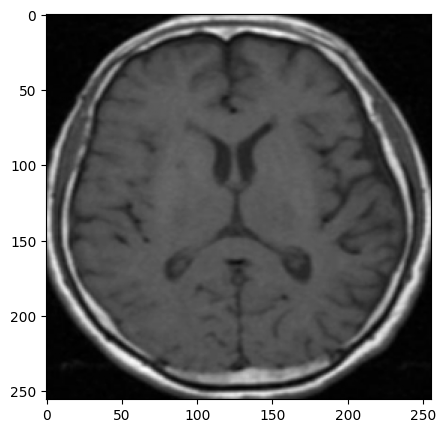

In [12]:
import matplotlib.pyplot as plt
%matplotlib inline
dataiter = iter(trainloader)
images, _ = next(dataiter)

images = images.numpy()

img = np.squeeze(images[0])

fig = plt.figure(figsize=(5,5))
ax = fig.add_subplot(111)
ax.imshow(img, cmap='gray')
plt.show()

In [13]:
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()
        
        # encoder
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 4, 3, padding=1)
        
        # decoder
        self.t_conv1 = nn.ConvTranspose2d(4, 16, 2, stride=2)
        self.t_conv2 = nn.ConvTranspose2d(16, 1, 2, stride=2)

    def forward(self, x):
        # encode
        x = torch.relu(self.conv1(x))
        x = self.pool(x)
        x = torch.relu(self.conv2(x))
        x = self.pool(x)
        
        # decode
        x = torch.relu(self.t_conv1(x))
        x = torch.sigmoid(self.t_conv2(x))
        
        return x

model = ConvAutoencoder().to(device)

In [14]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [15]:
n_epochs = 20

for epoch in range(n_epochs):
    train_loss = 0.0
    
    for images, _ in trainloader:
        
        images = images.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, images)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
    
    train_loss = train_loss / len(trainloader.dataset)
    
    print(f'Epoch: {epoch+1} \tTraining Loss: {train_loss:.6f}')

Epoch: 1 	Training Loss: 0.101727
Epoch: 2 	Training Loss: 0.100412
Epoch: 3 	Training Loss: 0.099111
Epoch: 4 	Training Loss: 0.097831
Epoch: 5 	Training Loss: 0.096502
Epoch: 6 	Training Loss: 0.095161
Epoch: 7 	Training Loss: 0.093862
Epoch: 8 	Training Loss: 0.092515
Epoch: 9 	Training Loss: 0.091155
Epoch: 10 	Training Loss: 0.089693
Epoch: 11 	Training Loss: 0.088130
Epoch: 12 	Training Loss: 0.086393
Epoch: 13 	Training Loss: 0.084445
Epoch: 14 	Training Loss: 0.082235
Epoch: 15 	Training Loss: 0.079603
Epoch: 16 	Training Loss: 0.076434
Epoch: 17 	Training Loss: 0.072774
Epoch: 18 	Training Loss: 0.068992
Epoch: 19 	Training Loss: 0.064878
Epoch: 20 	Training Loss: 0.060621


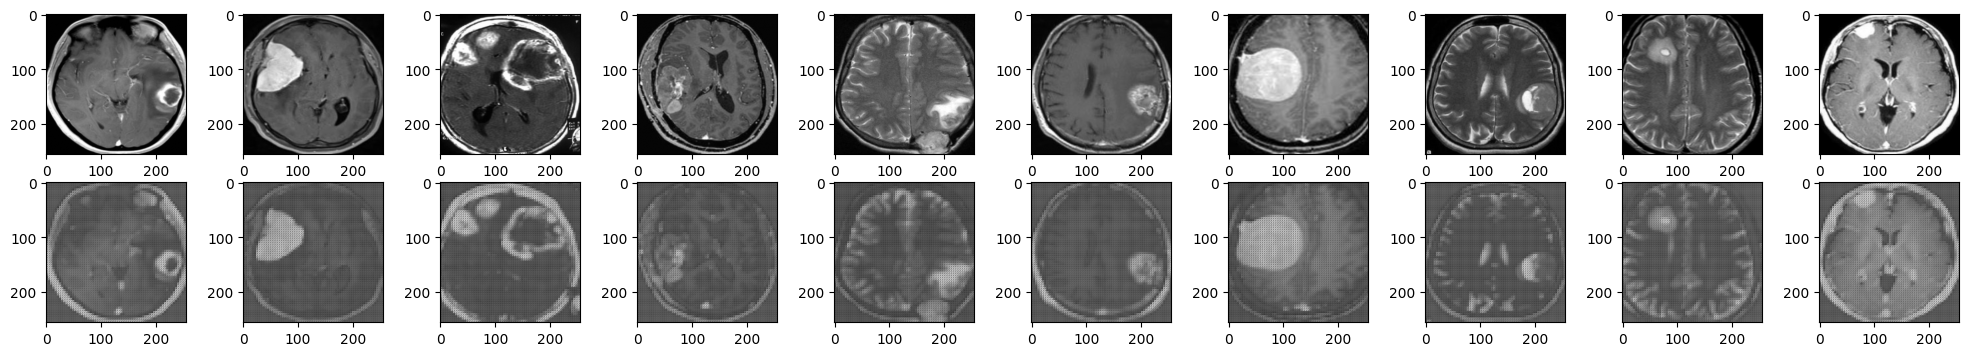

In [16]:
dataiter = iter(testloader)
images, labels = next(dataiter)

images = images.to(device)
output = model(images)

images = images.cpu().detach().numpy()
output = output.cpu().detach().numpy()

fig, axes = plt.subplots(2,10, figsize=(25,4))

for i in range(10):
    axes[0,i].imshow(np.squeeze(images[i]), cmap='gray')
    axes[1,i].imshow(np.squeeze(output[i]), cmap='gray')